# CNN Architecture Benchmark on CIFAR-10

**Computer Vision · PyTorch · CNN Architecture Comparison · Model Interpretability**

## Актуальность и постановка задачи

Сверточные нейронные сети применяются для классификации изображений, однако выбор размера ядра, глубины и шага свертки влияет как на качество распознавания, так и на вычислительную стоимость. В проекте исследуется компромисс между точностью и скоростью четырех архитектур CNN на CIFAR-10.

**Цель:** сравнить варианты сверточных блоков при сопоставимом рецептивном поле и проанализировать, какие области изображения влияют на предсказания модели.

**Данные:** CIFAR-10 — цветные изображения размером 32×32, 10 классов объектов.

**Методы:** CNN с ядрами 3×3, 7×7 + 1×1, 5×5 + 3×3 и 3×3 со stride=2; оптимизатор AdamW; анализ карт активаций; Occlusion Attribution (Captum).

**Метрики:** accuracy на обучающей и тестовой выборках, количество параметров, время прямого и обратного проходов. Для интерпретации используются карты активаций и окклюзионные карты важности.

**Эксперимент:** четыре архитектуры обучены на CIFAR-10 в сопоставимых условиях. Далее исследуется их эффективность и поведение на изображениях разных классов.


In [ ]:
!pip install torchinfo
!pip install captum

In [ ]:
import time
import numpy as np
from collections import defaultdict

import seaborn as sns
sns.set(palette='Set2')
import matplotlib.pyplot as plt
from IPython.display import clear_output

import torch
from torch import nn
import torch.nn.functional as F
from torchinfo import summary
import torchvision
from torchvision import transforms
from torchvision.models.feature_extraction import create_feature_extractor, get_graph_node_names
from captum.attr import Occlusion
import captum_visualization as viz

In [ ]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cpu'

## 1. Данные и архитектуры сверточных сетей

### 1.1. Датасет CIFAR-10

Загрузка обучающей и тестовой выборок CIFAR-10.

In [ ]:
# Часть данных для обучения
train_dataset = torchvision.datasets.CIFAR10(
    root='./cifar', download=True, train=True, transform=transforms.ToTensor()
)

# Валидационная / тестовая часть данных
val_dataset = torchvision.datasets.CIFAR10(
    root='./cifar', download=True, train=False, transform=transforms.ToTensor()
)

# Классы объектов в датасете
classes = (
    'plane', 'car', 'bird', 'cat',
    'deer', 'dog', 'frog', 'horse', 'ship', 'truck'
)

100%|██████████| 170498071/170498071 [00:01<00:00, 97456652.90it/s] 


Extracting ./cifar/cifar-10-python.tar.gz to ./cifar
Files already downloaded and verified


Проверка объема выборок.

In [ ]:
len(train_dataset), len(val_dataset)

(50000, 10000)

Примеры изображений из CIFAR-10.

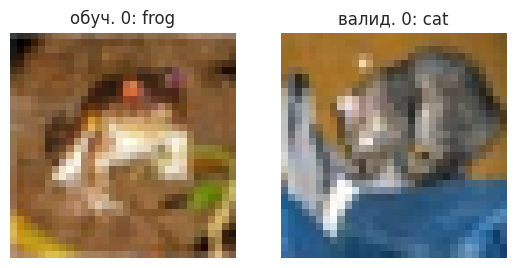

In [ ]:
train_idx, val_idx = 0, 0

plt.subplot(1, 2, 1)
plt.imshow(train_dataset[train_idx][0].permute(1, 2, 0))
plt.title(f'обуч. {train_idx}: {classes[train_dataset[train_idx][1]]}')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(val_dataset[val_idx][0].permute(1, 2, 0))
plt.title(f'валид. {val_idx}: {classes[val_dataset[val_idx][1]]}')
plt.axis('off')

plt.show()

Подготовка загрузчиков данных.

In [ ]:
batch_size = 64

train_batch_gen = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_batch_gen = torch.utils.data.DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

### 1.2. Базовая CNN: три сверточных слоя 3×3

Архитектура: $INPUT \to [CONV \to RELU]^3 \to POOL \to FC \to RELU \to FC$.

In [ ]:
class ConvNet1(nn.Module):
    def __init__(self):
        super(ConvNet1, self).__init__()

        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.conv3 = nn.Conv2d(64, 128, 3, padding=1)
        self.pool = nn.AvgPool2d(kernel_size=14)

        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(512, 256)
        self.dropout = nn.Dropout(p=0.2)
        self.fc2 = nn.Linear(256, 10)
        self.relu = nn.ReLU()

    def forward(self, x):
        out = x
        out = self.relu(self.conv1(out))
        out = self.relu(self.conv2(out))
        out = self.relu(self.conv3(out))
        out = self.flatten(self.pool(out))
        out = self.relu(self.dropout(self.fc1(out)))
        out = self.fc2(out)
        return out

Для базовой архитектуры оцениваются количество параметров, вычислительное время прямого и обратного проходов, динамика loss и accuracy. Веса и история обучения сохраняются для последующего анализа.

Для измерения времени GPU-операций используется таймер на основе `torch.cuda.Event`, учитывающий асинхронное выполнение вычислений.

In [ ]:
class GPUTimer:
    """
    Класс для корректной оценки времени вычислений на GPU.
    """
    def __init__(self):
        # Заводим starter и ender для оценки времени
        self._starter = torch.cuda.Event(enable_timing=True)
        self._ender = torch.cuda.Event(enable_timing=True)

        # Здесь записывается последняя запись времени
        self.record = None

    def __call__(self, func, *args, **kwargs):
        """
        Параметры
          func - объект, который можно вызвать, например функция;
          *args, **kwargs - аргументы для вызываемого объекта.
        """

        # Устанавливаем время старта
        self._starter.record()

        # Применяем функцию
        output = func(*args, **kwargs)

         # Устаналиваем время окончания
        self._ender.record()

        # Производим синхронизацию: ждем, когда вычиления на GPU будут окончены
        torch.cuda.synchronize()

        # Записываем прошедшее время
        self.record = self._starter.elapsed_time(self._ender)

        return output

Функция обучения и оценки модели.

In [ ]:
def train(
    model,
    criterion,
    optimizer,
    train_batch_gen,
    val_batch_gen,
    num_epochs=50,
    device='cuda'
):
    '''
    Функция для обучения модели и вывода лосса и метрики во время обучения.

    :param model: обучаемая модель
    :param criterion: функция потерь
    :param optimizer: метод оптимизации
    :param train_batch_gen: генератор батчей для обучения
    :param val_batch_gen: генератор батчей для валидации
    :param num_epochs: количество эпох

    :return: обученная модель
    :return: (dict) accuracy и loss на обучении и валидации ("история" обучения)
    '''
    # Объект таймера, класс которого мы определили ранее
    timer = GPUTimer()

    # Разогрев для корректного подсчета времени
    X_batch, y_batch  = next(iter(train_batch_gen))
    X_batch = X_batch.to(device)
    y_batch = y_batch.to(device).long()
    for _ in range(10):
        logits = timer(model, X_batch)
        loss = criterion(logits, y_batch)
        timer(loss.backward)

    # Здесь хранится история обучения
    history = defaultdict(lambda: defaultdict(list))

    for epoch in range(num_epochs):
        train_loss = 0
        train_acc = 0
        val_loss = 0
        val_acc = 0

        fw_records = []
        bw_records = []

        # Устанавливаем поведение dropout / batch_norm  в обучение
        model.train(True)

        start_time = time.time()

        # На каждой "эпохе" делаем полный проход по данным
        for X_batch, y_batch in train_batch_gen:

            # Обучаемся на батче (одна "итерация" обучения нейросети)
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device).long()

            # Логиты на выходе модели
            logits = timer(model, X_batch)

            # Записываем время требуемое на прямой проход по сети
            fw_records.append(timer.record)

            # Подсчитываем лосс
            loss = criterion(logits, y_batch)

            # Обратный проход
            timer(loss.backward)

            # Записываем время требуемое на прямой проход по сети
            bw_records.append(timer.record)

            # Шаг градиента
            optimizer.step()

            # Зануляем градиенты
            optimizer.zero_grad()

            # Сохраняем лоссы и точность на трейне
            train_loss += loss.detach().cpu().numpy()
            y_pred = logits.max(1)[1].detach().cpu().numpy()
            train_acc += np.mean(y_batch.cpu().numpy() == y_pred)

        # Подсчитываем метрики и сохраняем в "историю"
        fw_time = np.mean(fw_records)
        bw_time = np.mean(bw_records)
        train_loss /= len(train_batch_gen)
        train_acc /= len(train_batch_gen)
        history['time']['forward_pass'].append(fw_time)
        history['time']['backward_pass'].append(bw_time)
        history['loss']['train'].append(train_loss)
        history['acc']['train'].append(train_acc)

        # Устанавливаем поведение dropout / batch_norm в режим тестирования
        model.train(False)

        # Полный проход по валидации
        for X_batch, y_batch in val_batch_gen:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            # Логиты, полученные моделью
            logits = model(X_batch)

            # Лосс на валидации
            loss = criterion(logits, y_batch.long().to(device))

            # Сохраняем лоссы и точность на валидации
            val_loss += loss.detach().cpu().numpy()
            y_pred = logits.max(1)[1].detach().cpu().numpy()
            val_acc += np.mean(y_batch.cpu().numpy() == y_pred)

        # Подсчитываем лоссы и сохраняем в "историю"
        val_loss /= len(val_batch_gen)
        val_acc /= len(val_batch_gen)
        history['loss']['val'].append(val_loss)
        history['acc']['val'].append(val_acc)

        clear_output()

        # Печатаем результаты после каждой эпохи
        print(f"Epoch {epoch + 1} of {num_epochs} took {time.time() - start_time:.3f}s")
        print(f"Forward time: {fw_time:.2f} s")
        print(f"Backward time: {bw_time:.2f} s")
        print(f"Metrics:")
        print(f"  training loss (in-iteration): \t{train_loss:.6f}")
        print(f"  validation loss (in-iteration): \t{val_loss:.6f}")
        print(f"  training accuracy: \t\t\t{train_acc * 100:.2f} %")
        print(f"  validation accuracy: \t\t\t{val_acc * 100:.2f} %")

        plot_learning_curves(history)

    history = {key: dict(val) for key, val in history.items()}

    return model, history

Визуализация динамики обучения.

In [ ]:
def plot_learning_curves(history):
    '''
    Функция для вывода лосса и метрики во время обучения.
    :param history: (dict)
        accuracy и loss на обучении и валидации
    '''

    plt.figure(figsize=(20, 5))

    plt.subplot(1,3,1)
    plt.title('Лосс')
    plt.plot(history['loss']['train'], label='train', lw=3)
    plt.plot(history['loss']['val'], label='val', lw=3)
    plt.xlabel('Эпоха')
    plt.legend()

    plt.subplot(1,3,2)
    plt.title('Точность')
    plt.plot(history['acc']['train'], label='train', lw=3)
    plt.plot(history['acc']['val'], label='val', lw=3)
    plt.xlabel('Эпоха')
    plt.legend()

    plt.subplot(1,3,3)
    plt.title('Время на обучении')
    plt.plot(history['time']['forward_pass'], label='Прямой пр.', lw=3)
    plt.plot(history['time']['backward_pass'], label='Обратный пр.', lw=3)
    plt.xlabel('Эпоха')
    plt.legend()

    plt.show()

Оптимизатор AdamW и функция потерь CrossEntropyLoss.

In [ ]:
optimizer = torch.optim.AdamW(model1.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()

Обучение базовой архитектуры и сохранение результатов.

Epoch 50 of 50 took 17.930s
Forward time: 3.35 s
Backward time: 6.36 s
Metrics:
  training loss (in-iteration): 	0.334432
  validation loss (in-iteration): 	0.710907
  training accuracy: 			87.83 %
  validation accuracy: 			77.71 %


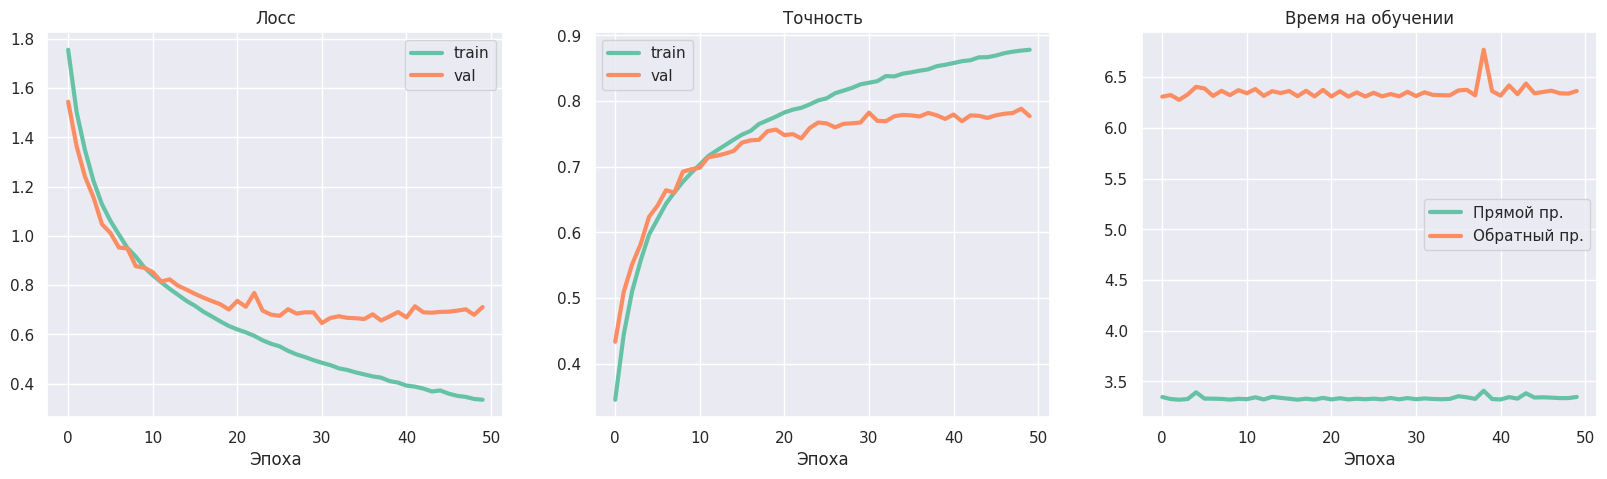

In [ ]:
model1, history1 = train(
    model1, criterion, optimizer,
    train_batch_gen, val_batch_gen,
    num_epochs=50,
    device=device,
)

torch.save(
    {
        'model':model1.state_dict(),
        'history': history1,
    },
    'model1.pth'
)

### 1.3. Рецептивное поле базовой модели

**Ответ:** Область видимости нейронов первого слоя сети составляет квадрат $3 \times 3$, второго слоя &mdash; $5 \times 5$, последнего &mdash; $7 \times 7$. Таким образом область картинки, которую видит каждый отдельный нейрон последнего слоя составляет $49$ пикселей.

## 2. Сравнение сверточных архитектур

Исследуются четыре варианта CNN с рецептивным полем 7×7 у последнего сверточного слоя: последовательные 3×3, комбинация 7×7 и 1×1, комбинация 5×5 и 3×3, а также свертки 3×3 с шагом 2. Для сопоставления вычислительных характеристик рассматривается сумма произведений числа входных и выходных каналов $\sum_k c_{k,in}c_{k,out}$.

Оценка суммарного числа сочетаний входных и выходных каналов для базовой модели.

In [ ]:
3 * 32 + 32 * 64 + 64 * 128

10336

Архитектура с ядрами 7×7 и 1×1.

In [ ]:
3 * 76 + 76 * 133

10336

In [ ]:
class ConvNet2(nn.Module):
    def __init__(self):
        super(ConvNet2, self).__init__()

        self.conv1 = nn.Conv2d(3, 76, 7, padding=3)
        self.conv2 = nn.Conv2d(76, 133, 1)
        self.pool = nn.AvgPool2d(kernel_size=14)

        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(532, 256)
        self.dropout = nn.Dropout(p=0.2)
        self.fc2 = nn.Linear(256, 10)

        self.relu = nn.ReLU()

    def forward(self, x):
        out = x
        out = self.relu(self.conv1(out))
        out = self.relu(self.conv2(out))
        out = self.flatten(self.pool(out))
        out = self.relu(self.dropout(self.fc1(out)))
        out = self.fc2(out)
        return out

Архитектура с ядрами 5×5 и 3×3.

In [ ]:
class ConvNet3(nn.Module):
    def __init__(self):
        super(ConvNet3, self).__init__()

        self.conv1 = nn.Conv2d(3, 76, 5, padding=2)
        self.conv2 = nn.Conv2d(76, 133, 3, padding=1)
        self.pool = nn.AvgPool2d(kernel_size=14)

        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(532, 256)
        self.dropout = nn.Dropout(p=0.2)
        self.fc2 = nn.Linear(256, 10)

        self.relu = nn.ReLU()

    def forward(self, x):
        out = x
        out = self.relu(self.conv1(out))
        out = self.relu(self.conv2(out))
        out = self.flatten(self.pool(out))
        out = self.relu(self.dropout(self.fc1(out)))
        out = self.fc2(out)
        return out

Архитектура со свертками 3×3 и шагом 2.

In [ ]:
class ConvNet4(nn.Module):
    def __init__(self):
        super(ConvNet4, self).__init__()

        self.conv1 = nn.Conv2d(3, 76, 3, padding=1, stride=2)
        self.conv2 = nn.Conv2d(76, 133, 3, padding=1, stride=2)
        self.pool = nn.AvgPool2d(kernel_size=4, stride=3)

        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(532, 256)
        self.dropout = nn.Dropout(p=0.2)
        self.fc2 = nn.Linear(256, 10)

        self.relu = nn.ReLU()

    def forward(self, x):
        out = x
        out = self.relu(self.conv1(out))
        out = self.relu(self.conv2(out))
        out = self.flatten(self.pool(out))
        out = self.relu(self.dropout(self.fc1(out)))
        out = self.fc2(out)
        return out

Все варианты обучаются с одинаковой конфигурацией оптимизатора и функцией потерь. Сравниваются качество классификации, число параметров и время вычислений.

In [ ]:
model2 = ConvNet2().to(device)
optimizer = torch.optim.AdamW(model2.parameters(), lr=0.001)
summary(model2)

Layer (type:depth-idx)                   Param #
ConvNet2                                 --
├─Conv2d: 1-1                            11,248
├─Conv2d: 1-2                            10,241
├─AvgPool2d: 1-3                         --
├─Flatten: 1-4                           --
├─Linear: 1-5                            136,448
├─Dropout: 1-6                           --
├─Linear: 1-7                            2,570
├─ReLU: 1-8                              --
Total params: 160,507
Trainable params: 160,507
Non-trainable params: 0

Архитектура 7×7 + 1×1 содержит 160 507 параметров, из которых 21 489 относятся к сверточным слоям (около 13%).

Epoch 50 of 50 took 16.583s
Forward time: 3.63 s
Backward time: 6.21 s
Metrics:
  training loss (in-iteration): 	0.559747
  validation loss (in-iteration): 	0.819314
  training accuracy: 			79.98 %
  validation accuracy: 			72.80 %


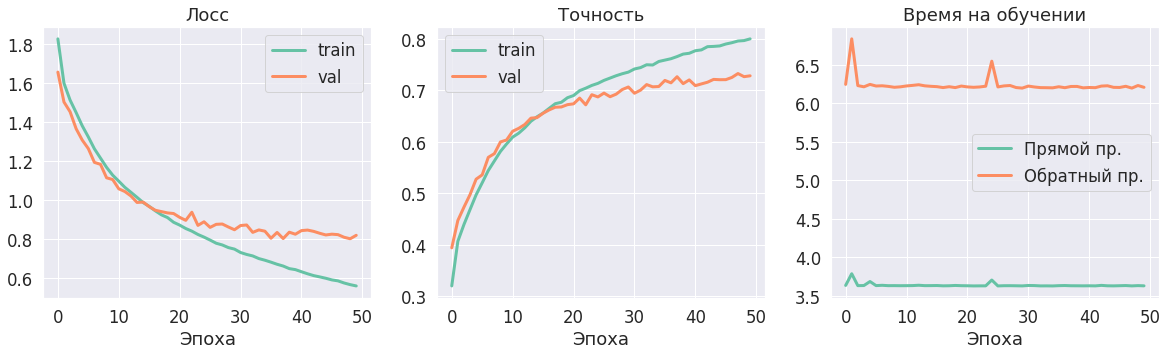

In [ ]:
model2, history2 = train(
    model2, criterion, optimizer,
    train_batch_gen, val_batch_gen,
    num_epochs=50
)

torch.save(
    {
        'model':model2.state_dict(),
        'history': history2
    },
    'model2.pth'
)

In [ ]:
model3 = ConvNet3().to(device)
optimizer = torch.optim.AdamW(model3.parameters(), lr=0.001)
summary(model3)

Layer (type:depth-idx)                   Param #
ConvNet3                                 --
├─Conv2d: 1-1                            5,776
├─Conv2d: 1-2                            91,105
├─AvgPool2d: 1-3                         --
├─Flatten: 1-4                           --
├─Linear: 1-5                            136,448
├─Dropout: 1-6                           --
├─Linear: 1-7                            2,570
├─ReLU: 1-8                              --
Total params: 235,899
Trainable params: 235,899
Non-trainable params: 0

Архитектура 5×5 + 3×3 содержит 235 899 параметров, из которых 96 881 относятся к сверточным слоям (около 41%).

Epoch 50 of 50 took 18.497s
Forward time: 3.30 s
Backward time: 9.02 s
Metrics:
  training loss (in-iteration): 	0.445278
  validation loss (in-iteration): 	0.779601
  training accuracy: 			84.00 %
  validation accuracy: 			75.58 %


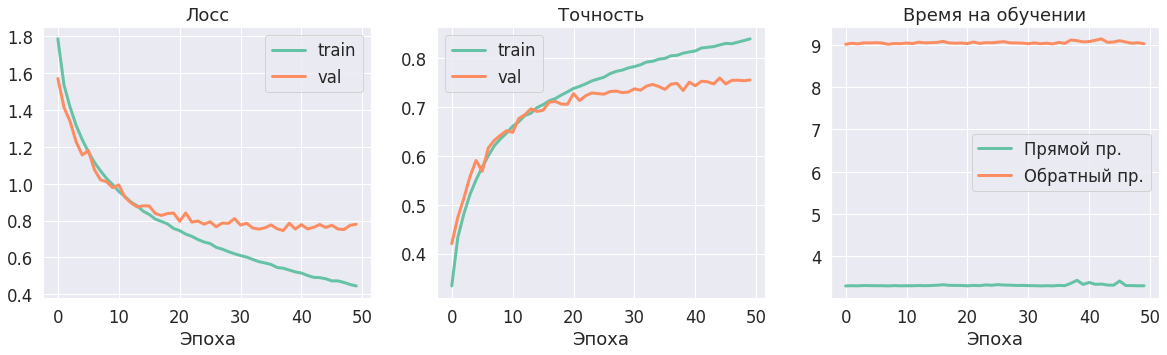

In [ ]:
model3, history3 = train(
    model3, criterion, optimizer,
    train_batch_gen, val_batch_gen,
    num_epochs=50
)

torch.save(
    {
        'model':model3.state_dict(),
        'history': history3
    },
    'model3.pth'
)

In [ ]:
model4 = ConvNet4().to(device)
optimizer = torch.optim.AdamW(model4.parameters(), lr=0.001)
summary(model4)

Layer (type:depth-idx)                   Param #
ConvNet4                                 --
├─Conv2d: 1-1                            2,128
├─Conv2d: 1-2                            91,105
├─AvgPool2d: 1-3                         --
├─Flatten: 1-4                           --
├─Linear: 1-5                            136,448
├─Dropout: 1-6                           --
├─Linear: 1-7                            2,570
├─ReLU: 1-8                              --
Total params: 232,251
Trainable params: 232,251
Non-trainable params: 0

Архитектура с шагом 2 содержит 232 251 параметр, из которых 93 233 относятся к сверточным слоям (около 40%).

Epoch 50 of 50 took 11.362s
Forward time: 0.96 s
Backward time: 2.30 s
Metrics:
  training loss (in-iteration): 	0.421920
  validation loss (in-iteration): 	0.991931
  training accuracy: 			84.64 %
  validation accuracy: 			70.97 %


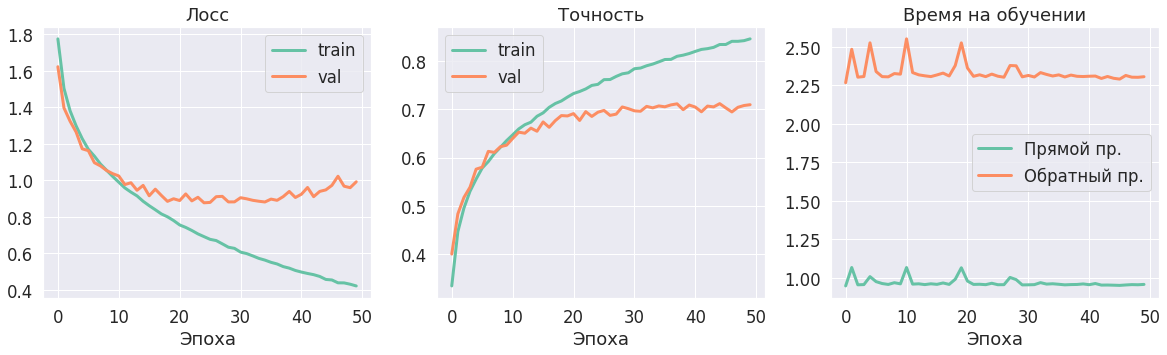

In [ ]:
model4, history4 = train(
    model4, criterion, optimizer,
    train_batch_gen, val_batch_gen,
    num_epochs=50
)

torch.save(
    {
        'model':model4.state_dict(),
        'history': history4
    },
    'model4.pth'
)

### 2.1. Сводное сравнение моделей

| Модель | # пар-в | # сверт. пар-в |% сверт. пар-в. |T прям. проход, с | T обр. проход, с | Точность на обуч. % | Точность на тесте %|
| --- | --- | --- | --- | --- | --- | --- | --- |
| 3 свертки 3 x 3 | 227 146 |  93 248 | 41 |3.4|6.3|87|78|
| 2 свертки: 7 x 7 и 1 x 1 | 160 507 | 21 489 | 13 | 3.6 | 6.2 | 80 | 73 |
| 2 свертки: 5 x 5 и 3 x 3 | 235 899 | 96 881 | 41 | 3.3 | 9.0 | 84 | 76 |
| 2 свертки 3 x 3 c шагом 2 |  232 251 | 93 233 | 40 | 1.0 | 2.3 | 85 | 71 |



**Анализ результатов:**

Мы рассмотрели четыре модели с одинаковым рецептивным полем и одинаковым количеством фильтров $\sum_{k} с_{k,in} c_{k, out}$.

Даже при одинаковом подходе к обучению точность у моделей получилась разная. Наилучшая точность вышла у модели с 3 свертками. Это можно объяснить тем, что последняя свертка данной модели работает с более абстрактными данными, чем последние свертки в других моделях, что позволяет ей лучше обрабатывать данные.

Количество параметров у всех получилось примерно одинаковым кроме модели со сверткой 7 x 7. Причиной для этого служит наличие сверток 1 x 1, у которых наименьшее количество параметров по сравнению с другими свертками. Данная модель при значительно меньшем количестве параметров уступает в качестве другим моделям, однако имеет потенциал для дальнейшего обучения. Таким образом такой подход является неплохим способом сжатия модели.

Наименьшее время на обучении получилось у модели со свертками с шагом 2, потому что такая модель производит значительно меньше вычислений. При этом качество у нее получилось наихудшим. Скорее всего проблема в том, что картинки слишком малы для того, чтобы пропускать какую-то информацию.

## 3. Интерпретируемость CNN

Для анализа внутренних представлений используются активации последнего сверточного слоя на изображениях самолетов и лягушек. Дополнительно применяется метод окклюзии из Captum к изображениям кораблей и собак.

Выбор индексов классов самолетов и лягушек.

In [ ]:
np.where(np.array(classes) == 'plane')[0][0], np.where(np.array(classes) == 'frog')[0][0]

(0, 6)

Выбор изображений для анализа карт активаций.

In [ ]:
# Находим индексы самолетов и лягушек
planes_ids, frogs_ids = [], []
for i, (img, label) in enumerate(train_dataset):
    if label == 0:
        planes_ids.append(i)
    elif label == 6:
        frogs_ids.append(i)

# Выбираем случайным образом индексы
planes_ids = np.random.choice(planes_ids, 5, replace=False)
frogs_ids = np.random.choice(frogs_ids, 5, replace=False)

# Собираем батчи из изображений самолетов и лягушек
planes_batch = torch.stack([train_dataset[i][0] for i in planes_ids])
frogs_batch = torch.stack([train_dataset[i][0] for i in frogs_ids])

Загрузка сохраненных весов базовой модели.

In [ ]:
model = ConvNet1()
model.load_state_dict(torch.load('model1.pth', map_location=torch.device('cpu'))['model'])
model.eval()

Для извлечения промежуточных активаций используется `torchvision.models.feature_extraction.create_feature_extractor`.

In [ ]:
train_nodes, eval_nodes = get_graph_node_names(model)
eval_nodes

['x',
 'conv1',
 'relu',
 'conv2',
 'relu_1',
 'conv3',
 'relu_2',
 'pool',
 'flatten',
 'fc1',
 'dropout',
 'relu_3',
 'fc2']

Извлечение выходов последнего сверточного слоя `conv3`.

In [ ]:
feature_extractor = create_feature_extractor(model, return_nodes=['conv3'])

Карты активаций для изображений самолетов.

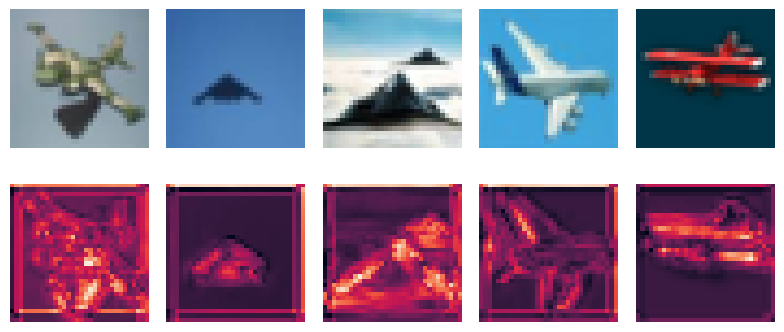

In [ ]:
planes_output = feature_extractor(planes_batch)['conv3'].detach()
planes_max_output = torch.max(planes_output, dim=1, keepdim=False).values
plt.figure(figsize=(8, 4))
for i in range(5):
    plt.subplot(2, 5, i + 1)
    plt.imshow(planes_batch[i].moveaxis(0, 2))
    plt.axis('off')
    plt.subplot(2, 5, 5 + i + 1)
    plt.imshow(planes_max_output[i])
    plt.axis('off')
plt.tight_layout()

Карты активаций для изображений лягушек.

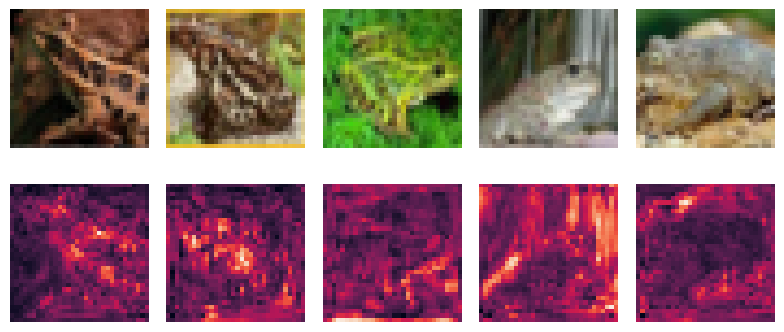

In [ ]:
frogs_output = feature_extractor(frogs_batch)['conv3'].detach()
frogs_max_output = torch.max(frogs_output, dim=1, keepdim=False).values
plt.figure(figsize=(8, 4))
for i in range(5):
    plt.subplot(2, 5, i + 1)
    plt.imshow(frogs_batch[i].moveaxis(0, 2))
    plt.axis('off')
    plt.subplot(2, 5, 5 + i + 1)
    plt.imshow(frogs_max_output[i])
    plt.axis('off')
plt.tight_layout()

**Вывод:** Можно заметить, что при обработке изображений с самолетами модель реагирует в основном на самолеты целиком и края изображения. Однако при обработке изображений с лягушками модель больше реагирует на какие-то детали: лапки лягушек, тени, яркие цветовые переходы, края изображения. Скорее всего это связано с тем, что у самолетов обычно монотонный фон и опредеять их легче.

### 3.1. Occlusion Attribution

Метод окклюзии оценивает изменение предсказания при последовательном скрытии участков изображения. Ниже представлены карты важности для классов кораблей и собак.

In [ ]:
ship_ids, dog_ids = [], []
for i, (img, label) in enumerate(train_dataset):
    if label == 8:
        ship_ids.append(i)
    elif label == 5:
        dog_ids.append(i)

# Выбираем случайным образом индексы
ship_rand_ids = np.random.choice(ship_ids, 5, replace=False)
dog_rand_ids = np.random.choice(dog_ids, 5, replace=False)

# Собираем батчи из изображений кораблей и собак
ships_batch = torch.stack([train_dataset[i][0] for i in ship_rand_ids])
dogs_batch = torch.stack([train_dataset[i][0] for i in dog_rand_ids])

# Делаем предсказания для батчей кораблей и собак
output = model(ships_batch)
output = F.softmax(output, dim=1)
prediction_score, ship_preds = torch.topk(output, 1)
ship_preds = ship_preds.flatten()
output = model(dogs_batch)
output = F.softmax(output, dim=1)
prediction_score, dog_preds = torch.topk(output, 1)
dog_preds = dog_preds.flatten()

Окклюзионные карты для класса кораблей.

predicted: ship


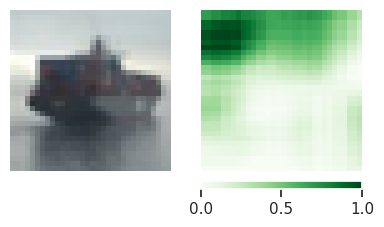

predicted: ship


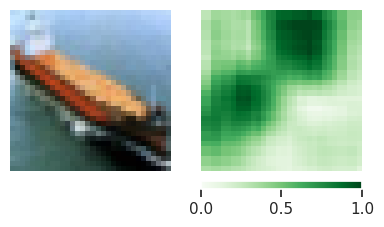

predicted: ship


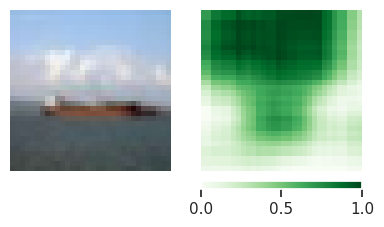

predicted: ship


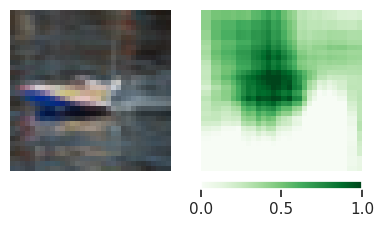

predicted: ship


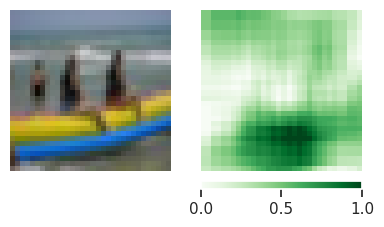

In [ ]:
occlusion = Occlusion(model)

for i, img in enumerate(ships_batch):
    img = img.unsqueeze(0)
    print("predicted:", classes[ship_preds[i]])
    # подсчет
    attributions_occ = occlusion.attribute(img, strides = (3, 2, 2),
                                           target=ship_preds[i],
                                           sliding_window_shapes=(3, 7, 7),
                                           baselines=0)
    # визуализация
    _ = viz.visualize_image_attr_multiple(np.transpose(attributions_occ.squeeze().cpu().detach().numpy(), (1,2,0)),
                                          np.transpose(img.squeeze().cpu().detach().numpy(), (1,2,0)),
                                          ["original_image", "heat_map"], ["all", "positive"],
                                          show_colorbar=True, outlier_perc=2, fig_size=(4, 2.5))

Окклюзионные карты для класса собак.

predicted: dog


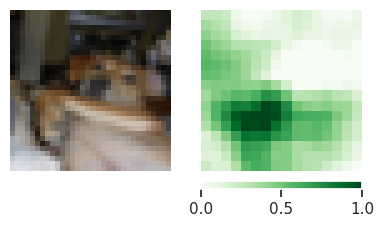

predicted: dog


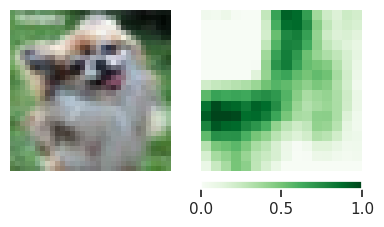

predicted: dog


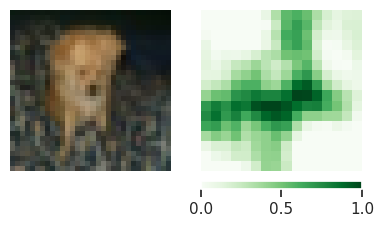

predicted: dog


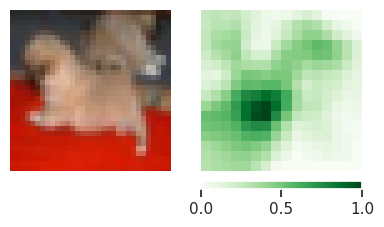

predicted: dog


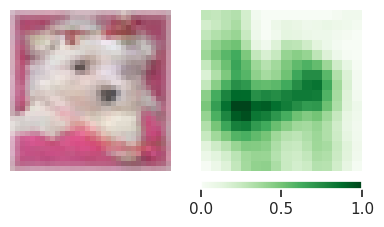

In [ ]:
for i, img in enumerate(dogs_batch):
    img = img.unsqueeze(0)
    print("predicted:", classes[dog_preds[i]])
    # подсчет
    attributions_occ = occlusion.attribute(img, strides = (3, 2, 2),
                                           target=dog_preds[i],
                                           sliding_window_shapes=(3, 6, 6),
                                           baselines=0)
    # визуализация
    _ = viz.visualize_image_attr_multiple(np.transpose(attributions_occ.squeeze().cpu().detach().numpy(), (1,2,0)),
                                          np.transpose(img.squeeze().cpu().detach().numpy(), (1,2,0)),
                                          ["original_image", "heat_map"], ["all", "positive"],
                                          show_colorbar=True, outlier_perc=2, fig_size=(4, 2.5))

А для определения класса собак модель считает важными лапы и текстуру / цвет шерсти.

## 4. Итоги исследования

По результатам экспериментов архитектура с тремя последовательными свертками 3×3 показала наибольшую тестовую точность (78%). Свертки с шагом 2 обеспечили минимальное время вычислений, но более низкую тестовую точность (71%). Использование 1×1-свертки позволило уменьшить число параметров модели. Карты активаций и метод окклюзии дают возможность визуально исследовать области изображений, влияющие на классификацию.